# Big Data Analytics (BDA) — Analitik Spasial & Integrasi Multimodal (Modifikasi Jurnal)

Pada **Jurnal Utama (Selayanti et al., 2024 — `10.46961/jommit.v8i2`)**, analisis berhenti pada klasterisasi 48 Sentra Wisata Kuliner (SWK) berbasis 4 variabel tabular tanpa pemetaan ketimpangan adopsi digital per kecamatan, tanpa bukti citra lapangan, dan tanpa analitik dokumen transaksi.

Tahap **Big Data Analytics (Modifikasi)** ini mengintegrasikan hasil 3 cabang (**Dataset A, B, C**) menjadi **Analitik Spasial 6 Kecamatan Surabaya Timur**:
1. **Tabulation & Grouped Bar Chart:** Penetrasi `QRIS`, `Ojol`, `POS`, `EDC`, skor kematangan, & `Digital Gap Index`.
2. **Digital Gap Ranking & Point Distribution Map (`lat`/`lon`):** Identifikasi wilayah prioritas intervensi digitalisasi UMKM.
3. **Spider Chart Multivariat:** Karakteristik 3 kelas kematangan digital (`Konvensional`, `Berkembang`, `Maju`).
4. **Integrasi SWK & Dokumen Transaksi:** Menghubungkan 48 SWK Kota Surabaya (Jurnal Utama), 44 stan survei offline SWK Sukolilo, dan profil pembayaran struk restoran Indonesia CORD-v2.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    display = print

if 'google.colab' in sys.modules:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')

def resolve_env(stage='bda'):
    cwd = Path.cwd().resolve()
    for base in [cwd, cwd.parent, cwd.parent.parent, cwd.parent.parent.parent]:
        if (base / 'data' / 'clean').exists() and (base / 'data' / 'gold').exists():
            out = base / 'docs' / 'reports' / stage
            out.mkdir(parents=True, exist_ok=True)
            return {
                'mode': 'local_repo', 'root': base, 'out_dir': out,
                'swk_csv': base / 'data' / 'raw' / 'journal_utama_swk' / 'kode11500kode25245kode3135.csv',
                'clean_tab': base / 'data' / 'clean',
                'photos_dir': base / 'data' / 'clean' / 'photos',
                'feat_store': base / 'data' / 'gold' / 'feature_store.parquet',
                'padang_dir': base / 'data' / 'raw' / 'journal_gambar_padang_id',
                'midd_dir': base / 'data' / 'raw' / 'journal_dokumen_midd' / 'IOB',
                'cord_file': base / 'data' / 'raw' / 'journal_dokumen_cord' / 'cord_v2_receipts_structured.parquet',
                'repeat_res': base / 'docs' / 'reports' / 'journal_repeat',
                'modif_res': base / 'docs' / 'reports' / 'journal_adjust',
                'eval_res': base / 'docs' / 'reports' / 'modeling',
                'bda_res': base / 'docs' / 'reports' / 'bda',
            }
    cands = [cwd, cwd.parent, Path('/content/drive/MyDrive/BDA-2026-Iqbal'), Path(r'G:\My Drive\BDA-2026-Iqbal')]
    if Path('/content/drive/MyDrive').exists():
        cands.extend(Path('/content/drive/MyDrive').glob('**/BDA-2026-Iqbal'))
    for dr in cands:
        if (dr / '04_Dataset_Multimodal_Saya').exists():
            out = dr / '07_Reports_Lengkap_Proyek' / stage
            out.mkdir(parents=True, exist_ok=True)
            return {
                'mode': 'gdrive', 'root': dr, 'out_dir': out,
                'swk_csv': dr / 'Repeat' / 'dataset_jurnal_utama' / 'kode11500kode25245kode3135.csv',
                'clean_tab': dr / '04_Dataset_Multimodal_Saya' / '02_clean' / 'tabular_text',
                'photos_dir': dr / '04_Dataset_Multimodal_Saya' / '02_clean' / 'images',
                'feat_store': dr / '04_Dataset_Multimodal_Saya' / '04_feature_store' / 'feature_store.parquet',
                'padang_dir': dr / 'Modifikasi' / 'dataset_gambar_indonesia_serupa',
                'midd_dir': dr / 'Modifikasi' / 'dataset_dokumen_tambahan' / 'MIDD_Invoice_IOB',
                'cord_file': dr / 'Modifikasi' / 'dataset_dokumen_tambahan' / 'CORD_v2_Receipts_Indonesia' / 'cord_v2_receipts_structured.parquet',
                'repeat_res': dr / 'Repeat' / 'hasil_repeat',
                'modif_res': dr / 'Modifikasi' / 'hasil_modifikasi',
                'eval_res': dr / '07_Reports_Lengkap_Proyek' / 'model_evaluation',
                'bda_res': dr / '07_Reports_Lengkap_Proyek' / 'bda',
            }
    raise FileNotFoundError('Workspace lokal atau Google Drive BDA-2026-Iqbal tidak ditemukan!')

ENV = resolve_env()
if ENV['mode'] == 'local_repo' and str(ENV['root']) not in sys.path:
    sys.path.insert(0, str(ENV['root']))

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

def save_and_show(filename: str) -> None:
    out_path = ENV['out_dir'] / filename
    plt.tight_layout()
    plt.savefig(out_path, dpi=180, bbox_inches='tight')
    print(f'Saved: {out_path}')
    plt.show()

print(f"Mode Aktif   : {ENV['mode']}")
print(f"Project Root : {ENV['root']}")
print(f"Output Dir   : {ENV['out_dir']}")

Mode Aktif   : local_repo
Project Root : C:\big-data-analytic
Output Dir   : C:\big-data-analytic\docs\reports\bda


## 1. Tabulation & Grouped Bar Chart — Penetrasi Indikator Digital per Kecamatan

,kecamatan,total_umkm,qris_rate,ojol_rate,pos_rate,edc_rate,avg_rating,avg_maturity_score,digital_gap_index,rekomendasi_intervensi
0,Gubeng,172,14.53,9.30,4.65,0.00,4.56,11.88,88.12,Prioritas Tinggi (Pendampingan Intensif QRIS &...
1,Gunung Anyar,50,16.00,22.00,2.00,0.00,4.55,14.75,85.25,Prioritas Tinggi (Pendampingan Intensif QRIS &...
2,Tenggilis Mejoyo,42,26.19,14.29,7.14,0.00,4.47,16.80,83.20,Prioritas Tinggi (Pendampingan Intensif QRIS &...
3,Rungkut,59,28.81,18.64,0.00,3.39,4.56,17.65,82.35,Prioritas Tinggi (Pendampingan Intensif QRIS &...
4,Sukolilo,35,31.43,20.00,5.71,2.86,4.60,19.91,80.09,Prioritas Tinggi (Pendampingan Intensif QRIS &...
5,Mulyorejo,27,44.44,22.22,7.41,0.00,4.56,23.97,76.03,Prioritas Menengah (Akselerasi POS Kasir Digital)


Saved: C:\big-data-analytic\docs\reports\bda\01_penetrasi_digital_kecamatan.png


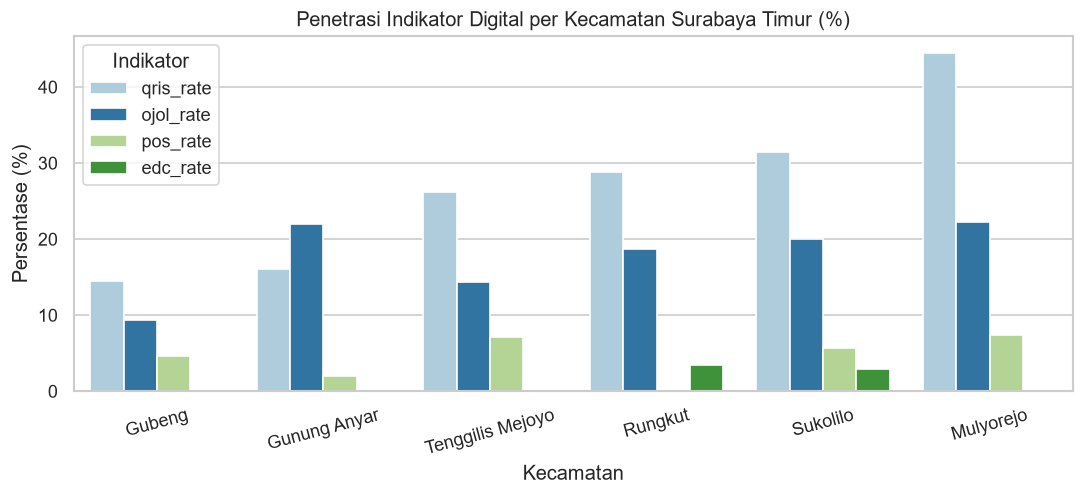

In [2]:
df_gap = pd.read_csv(ENV['bda_res'] / 'kecamatan_digital_gap.csv')
display(df_gap)

melted = df_gap.melt(
    id_vars='kecamatan',
    value_vars=['qris_rate', 'ojol_rate', 'pos_rate', 'edc_rate'],
    var_name='Indikator',
    value_name='Persentase (%)',
)
plt.figure(figsize=(9.2, 4.3))
sns.barplot(data=melted, x='kecamatan', y='Persentase (%)', hue='Indikator', palette='Paired')
plt.title('Penetrasi Indikator Digital per Kecamatan Surabaya Timur (%)')
plt.xlabel('Kecamatan')
plt.xticks(rotation=15)
save_and_show('01_penetrasi_digital_kecamatan.png')

## 2. Digital Gap Index & Point Distribution Map (`lat`/`lon`)

Saved: C:\big-data-analytic\docs\reports\bda\02_gap_index_dan_peta_sebaran.png


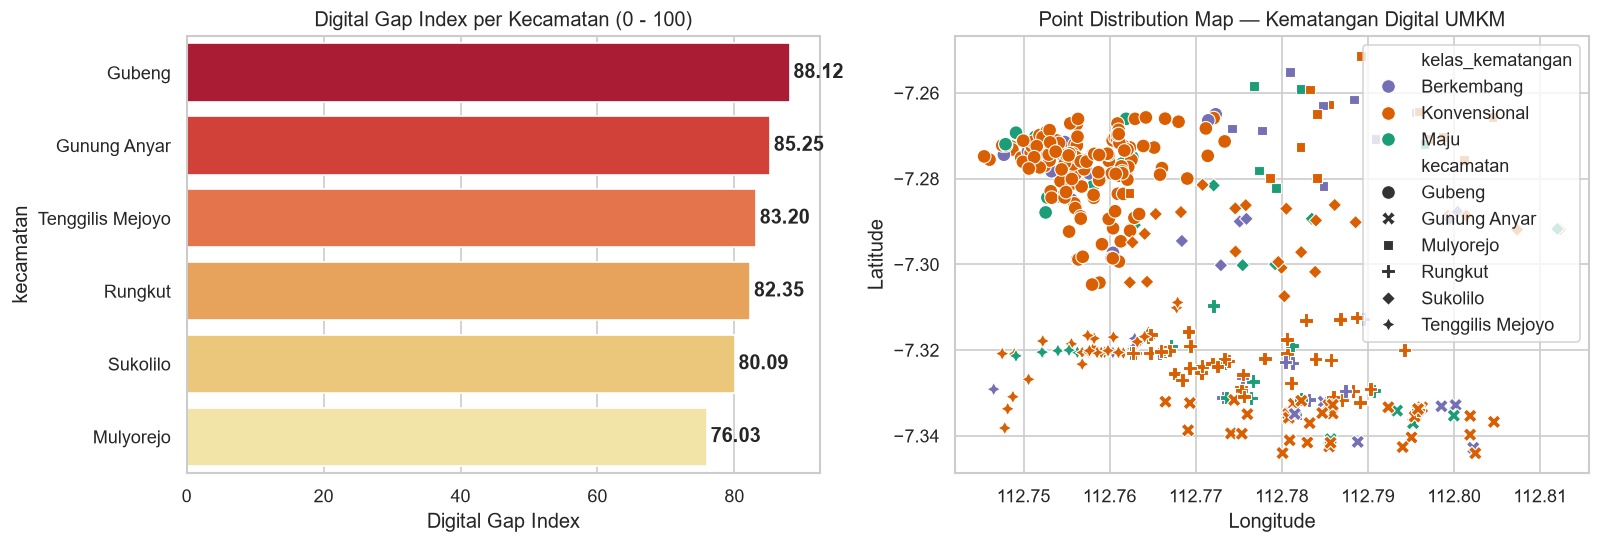

In [3]:
df_feat = pd.read_parquet(ENV['feat_store'])
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7))

sns.barplot(data=df_gap, x='digital_gap_index', y='kecamatan', hue='kecamatan', palette='YlOrRd_r', legend=False, ax=axes[0])
axes[0].set_title('Digital Gap Index per Kecamatan (0 - 100)')
axes[0].set_xlabel('Digital Gap Index')
for idx, val in enumerate(df_gap['digital_gap_index']):
    axes[0].text(val + 0.5, idx, f'{val:.2f}', va='center', fontweight='bold')

sns.scatterplot(
    data=df_feat, x='lon', y='lat', hue='kelas_kematangan', style='kecamatan',
    palette={'Konvensional': '#d95f02', 'Berkembang': '#7570b3', 'Maju': '#1b9e77'},
    s=68, ax=axes[1],
)
axes[1].set_title('Point Distribution Map — Kematangan Digital UMKM')
axes[1].set_xlabel('Longitude'); axes[1].set_ylabel('Latitude')
save_and_show('02_gap_index_dan_peta_sebaran.png')

## 3. Spider Chart — Profil Multivariat 3 Kelas Kematangan Digital

,indikator_qris,indikator_ojol,indikator_pos,indikator_edc
kelas_kematangan,,,,
Berkembang,64.71,21.57,13.73,0.00
Konvensional,0.00,0.00,0.00,0.00
Maju,98.08,88.46,17.31,5.77


Saved: C:\big-data-analytic\docs\reports\bda\03_spider_chart_profil_klaster.png


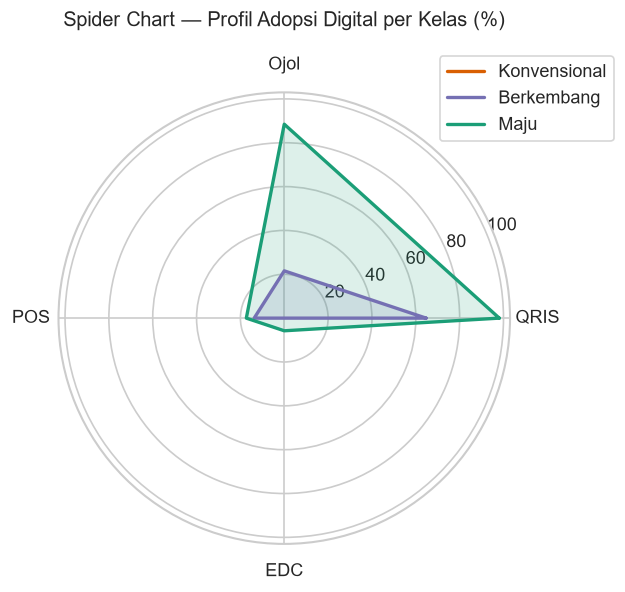

In [4]:
radar_cols = ['indikator_qris', 'indikator_ojol', 'indikator_pos', 'indikator_edc']
radar_labels = ['QRIS', 'Ojol', 'POS', 'EDC']
prof = df_feat.groupby('kelas_kematangan')[radar_cols].mean() * 100.0
display(prof.round(2))

angles = np.linspace(0, 2 * np.pi, len(radar_labels), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(5.5, 5.1), subplot_kw=dict(polar=True))
colors = {'Konvensional': '#d95f02', 'Berkembang': '#7570b3', 'Maju': '#1b9e77'}
for kelas in ['Konvensional', 'Berkembang', 'Maju']:
    if kelas in prof.index:
        vals = prof.loc[kelas].tolist() + [prof.loc[kelas].tolist()[0]]
        ax.plot(angles, vals, linewidth=2, label=kelas, color=colors[kelas])
        ax.fill(angles, vals, alpha=0.15, color=colors[kelas])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_labels)
ax.set_title('Spider Chart — Profil Adopsi Digital per Kelas (%)', pad=18)
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1))
save_and_show('03_spider_chart_profil_klaster.png')

## 4. Integrasi Klaster 48 SWK (Jurnal Utama), Survei Lapangan SWK, & Profil Struk Indonesia CORD-v2

In [5]:
df_swk_clustered = pd.read_csv(ENV['repeat_res'] / 'swk_surabaya_clustered_48.csv')
df_umkm = pd.read_parquet(ENV['clean_tab'] / 'umkm.parquet')
df_foto = pd.read_parquet(ENV['clean_tab'] / 'foto.parquet')
df_cord = pd.read_parquet(ENV['cord_file'])

swk_maps = df_umkm[df_umkm['tipe_lokasi'] == 'SWK']
swk_offline = df_foto[df_foto['sumber'] == 'survei_lapangan_swk']

print('Distribusi 48 SWK Kota Surabaya (Jurnal Utama):', df_swk_clustered['Cluster_AHC'].value_counts().sort_index().to_dict())
print(f'SWK Surabaya Timur pada Google Maps API       : {len(swk_maps)} lokasi')
print(f'Stan Survei Lapangan SWK Sukolilo (Offline)   : {len(swk_offline)} stan ({swk_offline["label_ground_truth"].value_counts().to_dict()})')
print('Metode Pembayaran 200 Struk Restoran CORD-v2  :', df_cord['payment_method'].value_counts().to_dict())
display(swk_maps[['umkm_id', 'nama_umkm', 'kecamatan', 'rating', 'alamat']])

Distribusi 48 SWK Kota Surabaya (Jurnal Utama): {1: 4, 2: 43, 3: 1}
SWK Surabaya Timur pada Google Maps API       : 7 lokasi
Stan Survei Lapangan SWK Sukolilo (Offline)   : 44 stan ({'Maju': 19, 'Berkembang': 16, 'Konvensional': 9})
Metode Pembayaran 200 Struk Restoran CORD-v2  : {'Tunai (Cash)': 130, 'Non-Tunai (Card/E-Money)': 35, 'Tidak Tercatat': 35}


,umkm_id,nama_umkm,kecamatan,rating,alamat
0,UMKM_SBY_0001,Sentra Wisata Kuliner Bratang Binangun,Gubeng,4.5,"Jl. Raya Manyar No.80A, Baratajaya, Kec. Guben..."
50,UMKM_SBY_0051,Sentra Wisata Kuliner Dharmahusada,Mulyorejo,4.4,"Pojok Timur, Jl. Dharmahusada, Mulyorejo, Kec...."
55,UMKM_SBY_0056,Sentra Wisata Kuliner Convention Hall,Sukolilo,4.3,"Arief Rahman Hakim No.131, Keputih, Kec. Sukol..."
70,UMKM_SBY_0071,Sentra Wisata Kuliner (SWK) Rungkut Kidul,Rungkut,4.9,"Jl. Rungkut Asri No.3, Rungkut Kidul, Kec. Run..."
91,UMKM_SBY_0092,Sentra Wisata Kuliner Semolowaru,Sukolilo,4.4,"Semolowaru, Sukolilo, Surabaya, East Java 6011..."
93,UMKM_SBY_0094,Wisata Kuliner Deles,Sukolilo,4.4,"Arief Rahman Hakim No.14, Keputih, Kec. Sukoli..."
375,UMKM_SBY_0376,SWK Klampis Ngasem,Sukolilo,4.4,"Jl. Dr. Ir. H. Soekarno, Klampis Ngasem, Kec. ..."
